# 02 - Data Cleaning & Standardization: Pemerataan Fasilitas Kesehatan Indonesia

**Tujuan Notebook**
1. **Eliminasi Baris Non-Wilayah**: Memfilter baris agregasi nasional (`Indonesia`), keterangan, dan catatan kaki (*footnotes*) BPS & Kemenkes.
2. **Standarisasi 38 Provinsi**: Memvalidasi seluruh nama provinsi agar sesuai dengan 38 entitas provinsi resmi di Indonesia (termasuk 4 Daerah Otonom Baru di Papua: Papua Selatan, Papua Tengah, Papua Pegunungan, dan Papua Barat Daya).
3. **Penanganan Token Nilai Hilang (Missing Tokens)**: Mengonversi simbol khusus (`\ufffd`, `-`, string kosong) menjadi nilai numerik atau representasi `NaN` yang baku.
4. **Strategi Penanganan Missing Values Spesifik**:
   - **RS Khusus**: Terdapat 6 provinsi yang tidak memiliki catatan RS Khusus (Kaltara & 5 provinsi Papua). Dibuat kolom flag `rs_khusus_is_missing` dan versi estimasi `total_rs_est` dengan asumsi RS Khusus = 0.
   - **Balai Kesehatan**: Terdapat 21 provinsi dengan status missing. Dibuat flag `balai_kesehatan_is_missing`.
5. **Standarisasi Penamaan Kolom**: Mengubah seluruh penamaan kolom ke format baku *snake_case* yang intuitif dan terstandarisasi.
6. **Validasi & Rekonsiliasi**: Melakukan *cross-check* penjumlahan 38 provinsi terhadap baris agregat nasional `Indonesia`.
7. **Ekspor Data Interim**: Menyimpan dataset bersih per domain dan dataset gabungan ke dalam folder `data/interim/` untuk tahapan rekayasa fitur (*feature engineering*).


## 0. Setup & Import Libraries


In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Deteksi root repository secara dinamis
current_path = Path.cwd().resolve()
ROOT = None
for candidate in [current_path] + list(current_path.parents):
    if (candidate / "src").exists() and (candidate / "data").exists():
        ROOT = candidate
        break
    elif (candidate / "pemerataan-faskes-indonesia" / "src").exists():
        ROOT = candidate / "pemerataan-faskes-indonesia"
        break

if ROOT is None:
    ROOT = current_path

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
INTERIM.mkdir(parents=True, exist_ok=True)

from src.config import PROVINSI_RESMI_38, MISSING_TOKENS
from src.data_loader import (
    load_all_raw,
    load_raw_penduduk,
    load_raw_desa,
    load_raw_sarana_desa,
    load_raw_rs_puskesmas
)
from src.cleaning import (
    clean_province_name,
    clean_series_numeric,
    clean_penduduk_data,
    clean_desa_data,
    clean_sarana_desa_data,
    clean_rs_puskesmas_data,
    merge_cleaned_datasets,
    validate_cleaning_results
)

# Plotting theme
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]

print("ROOT   :", ROOT)
print("RAW    :", RAW)
print("INTERIM:", INTERIM)


ROOT   : C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia
RAW    : C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\raw
INTERIM: C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\interim


## 1. Audit Kualitas Data Mentah (Before Cleaning)
Mengidentifikasi masalah kualitas data yang ditemukan pada tahap *Data Understanding*:
1. Baris non-wilayah (agregasi `Indonesia`, keterangan, catatan kaki).
2. Tipe data kolom numerik yang masih berupa `string/object`.
3. Token karakter khusus nilai hilang (`\ufffd`, `-`, dll.).
4. Nilai desimal yang memakai koma `,`.


In [2]:
raw_files = {
    "penduduk": "penduduk_provinsi_2026.csv",
    "desa": "desa_kelurahan_provinsi_2025.csv",
    "sarana_desa": "desa_kelurahan_sarana_kesehatan_2025.csv",
    "rs_puskesmas": "rs_puskesmas_provinsi_2025.csv"
}

audit_records = []
for name, fname in raw_files.items():
    df_raw = pd.read_csv(RAW / fname, dtype=str, keep_default_na=False)
    n_rows = len(df_raw)
    n_cols = len(df_raw.columns)
    
    # Cek baris footer/non-provinsi
    footers = df_raw["Provinsi"][df_raw["Provinsi"].apply(clean_province_name).isna()].tolist()
    
    # Deteksi token non-digit
    all_tokens = set()
    for col in df_raw.columns:
        if col != "Provinsi":
            non_num = df_raw[col][~df_raw[col].str.replace(".", "", regex=False).str.isdigit()].unique()
            all_tokens.update(non_num)
            
    audit_records.append({
        "Dataset": name,
        "File CSV": fname,
        "Total Baris Mentah": n_rows,
        "Total Kolom": n_cols,
        "Baris Non-Provinsi": len(footers),
        "Contoh Token Anomali": str(list(all_tokens)[:5] if all_tokens else "Tidak ada")
    })

df_audit = pd.DataFrame(audit_records)
display(df_audit)


,Dataset,File CSV,Total Baris Mentah,Total Kolom,Baris Non-Provinsi,Contoh Token Anomali
0,penduduk,penduduk_provinsi_2026.csv,42,6,4,['']
1,desa,desa_kelurahan_provinsi_2025.csv,39,2,1,Tidak ada
2,sarana_desa,desa_kelurahan_sarana_kesehatan_2025.csv,43,8,5,"['', '–']"
3,rs_puskesmas,rs_puskesmas_provinsi_2025.csv,42,5,4,"['', '–']"


## 2. Pembersihan Dataset per Domain


### 2.1 Standardisasi Nama 38 Provinsi & Eliminasi Baris Non-Wilayah
Memastikan seluruh nama provinsi konsisten dengan 38 entitas resmi di Indonesia, menghilangkan spasi ganda, dan membuang baris metadata.


In [3]:
test_cases = [
    "Aceh",
    "  DKI Jakarta  ",
    "di yogyakarta",
    "Papua Pegunungan",
    "Indonesia",
    "Keterangan",
    "1Proyeksi Penduduk Indonesia..."
]
print(f"{'Input String':32s} -> {'Hasil Standarisasi':20s}")
print("-" * 55)
for tc in test_cases:
    res = clean_province_name(tc)
    print(f"{repr(tc):32s} -> {repr(res)}")


Input String                     -> Hasil Standarisasi  
-------------------------------------------------------
'Aceh'                           -> 'Aceh'
'  DKI Jakarta  '                -> 'DKI Jakarta'
'di yogyakarta'                  -> 'DI Yogyakarta'
'Papua Pegunungan'               -> 'Papua Pegunungan'
'Indonesia'                      -> None
'Keterangan'                     -> None
'1Proyeksi Penduduk Indonesia...' -> None


### 2.2 Pembersihan Dataset Kependudukan (2026)
Proses:
- Standarisasi penamaan kolom snake_case
- Konversi tipe data numerik
- Pembentukan kolom `total_penduduk_jiwa` = `jumlah_penduduk_ribu * 1000`


In [4]:
raw_pend = load_raw_penduduk()
clean_pend = clean_penduduk_data(raw_pend)

print(f"Shape penduduk bersih: {clean_pend.shape}")
print(f"Jumlah provinsi unik : {clean_pend['provinsi'].nunique()}")
print(f"Total Penduduk Jiwa  : {clean_pend['total_penduduk_jiwa'].sum():,}")
print(f"Missing values total : {clean_pend.isna().sum().sum()}")
display(clean_pend.head(5))


Shape penduduk bersih: (38, 7)
Jumlah provinsi unik : 38
Total Penduduk Jiwa  : 287,198,400
Missing values total : 0


,provinsi,jumlah_penduduk_ribu,laju_pertumbuhan_tahunan_persen,persentase_penduduk_nasional,kepadatan_penduduk_km2,rasio_jenis_kelamin,total_penduduk_jiwa
0,Aceh,5695.9,1.34,1.98,100,100.9,5695900
1,Bali,4488.2,0.68,1.56,804,100.2,4488200
2,Banten,12641.3,1.05,4.40,1351,103.1,12641300
3,Bengkulu,2163.3,1.28,0.75,108,104.1,2163300
4,DI Yogyakarta,3802.7,0.63,1.32,1199,97.7,3802700


### 2.3 Pembersihan Dataset Jumlah Desa/Kelurahan (2025)
Proses:
- Standarisasi nama kolom `jumlah_desa`
- Konversi tipe data ke integer


In [5]:
raw_desa = load_raw_desa()
clean_desa = clean_desa_data(raw_desa)

print(f"Shape desa bersih   : {clean_desa.shape}")
print(f"Jumlah desa nasional: {clean_desa['jumlah_desa'].sum():,}")
display(clean_desa.head(5))


Shape desa bersih   : (38, 2)
Jumlah desa nasional: 84,291


,provinsi,jumlah_desa
0,Aceh,6513
1,Bali,718
2,Banten,1552
3,Bengkulu,1513
4,DI Yogyakarta,438


### 2.4 Pembersihan Dataset Sarana Kesehatan Desa (2025)
Dataset ini mencatat berapa banyak desa/kelurahan di tiap provinsi yang memiliki sarana kesehatan:
- Rumah Sakit, Puskesmas, Pustu, Apotek, Klinik Utama, Balai Kesehatan, Klinik Pratama.
- **Catatan Kualitas Data**: Balai Kesehatan memiliki 21 provinsi berstatus missing (`\ufffd`). Dibuat kolom penanda `balai_kesehatan_is_missing` dan nilai diimputasi 0 untuk menghindari error perhitungan agregat.


In [6]:
raw_sarana = load_raw_sarana_desa()
clean_sarana = clean_sarana_desa_data(raw_sarana)

print(f"Shape sarana desa bersih: {clean_sarana.shape}")
print(f"Provinsi dengan Balai Kesehatan missing: {clean_sarana['balai_kesehatan_is_missing'].sum()}")
display(clean_sarana.head(5))


Shape sarana desa bersih: (38, 9)
Provinsi dengan Balai Kesehatan missing: 21


,provinsi,desa_memiliki_rs,desa_memiliki_puskesmas,desa_memiliki_pustu,desa_memiliki_apotek,desa_memiliki_klinik_utama,desa_memiliki_balai_kesehatan,desa_memiliki_klinik_pratama,balai_kesehatan_is_missing
0,Aceh,71,369,965,575,48,1,223,False
1,Bali,63,122,478,313,42,0,136,True
2,Banten,113,251,210,559,62,1,515,False
3,Bengkulu,25,179,361,223,7,0,73,True
4,DI Yogyakarta,68,120,225,263,37,0,154,True


### 2.5 Pembersihan Dataset RS dan Puskesmas (2025)
Dataset ini mencatat jumlah fisik unit Rumah Sakit dan Puskesmas:
- `jumlah_rs_umum`, `jumlah_rs_khusus`, `jumlah_puskesmas_rawat_inap`, `jumlah_puskesmas_non_rawat_inap`
- **Catatan Kualitas Data**: RS Khusus tidak memiliki catatan di 6 provinsi (Kalimantan Utara, Papua Barat, Papua Barat Daya, Papua Selatan, Papua Tengah, Papua Pegunungan).
- **Solusi**:
  1. `jumlah_rs_khusus`: tetap mempertahankan `NaN` agar transparan saat analisis spesifik RSK.
  2. `rs_khusus_is_missing`: boolean flag penanda.
  3. `jumlah_rs_khusus_imputed`: versi imputasi 0.
  4. `total_rs`: RSU + RSK (bernilai NaN di 6 provinsi).
  5. `total_rs_est`: RSU + RSK Imputasi 0 (memungkinkan estimasi agregat nasional tanpa kehilangan baris).
  6. `total_puskesmas`: PKM Rawat Inap + Non-Rawat Inap.


In [7]:
raw_rs = load_raw_rs_puskesmas()
clean_rs = clean_rs_puskesmas_data(raw_rs)

print(f"Shape RS & Puskesmas bersih: {clean_rs.shape}")
missing_rsk_provs = clean_rs[clean_rs['rs_khusus_is_missing']]['provinsi'].tolist()
print(f"Provinsi RS Khusus missing ({len(missing_rsk_provs)}): {missing_rsk_provs}")
display(clean_rs.head(5))


Shape RS & Puskesmas bersih: (38, 10)
Provinsi RS Khusus missing (6): ['Kalimantan Utara', 'Papua Barat', 'Papua Barat Daya', 'Papua Pegunungan', 'Papua Selatan', 'Papua Tengah']


,provinsi,jumlah_rs_umum,jumlah_rs_khusus,jumlah_rs_khusus_imputed,rs_khusus_is_missing,total_rs,total_rs_est,jumlah_puskesmas_rawat_inap,jumlah_puskesmas_non_rawat_inap,total_puskesmas
0,Aceh,77,9.0,9,False,86.0,86,174,192,366
1,Bali,66,16.0,16,False,82.0,82,38,82,120
2,Banten,111,25.0,25,False,136.0,136,63,190,253
3,Bengkulu,25,3.0,3,False,28.0,28,52,127,179
4,DI Yogyakarta,64,16.0,16,False,80.0,80,47,74,121


## 3. Rekonsiliasi & Validasi Integritas Data
Memvalidasi total angka dari 38 provinsi bersih terhadap baris agregat nasional `Indonesia` pada dataset mentah BPS.


In [8]:
def get_national_raw_val(df_raw, col_name):
    row = df_raw[df_raw["Provinsi"].str.strip().str.lower() == "indonesia"]
    if len(row) > 0:
        val_str = str(row[col_name].iloc[0]).strip().replace(",", ".")
        return float(val_str)
    return np.nan

validation_table = [
    {
        "Indikator": "Penduduk (Ribu Jiwa)",
        "Sum 38 Provinsi": clean_pend["jumlah_penduduk_ribu"].sum(),
        "Baris 'Indonesia' BPS": get_national_raw_val(raw_pend, "Jumlah Penduduk (Ribu)"),
        "Selisih": abs(clean_pend["jumlah_penduduk_ribu"].sum() - get_national_raw_val(raw_pend, "Jumlah Penduduk (Ribu)"))
    },
    {
        "Indikator": "Jumlah Desa/Kelurahan",
        "Sum 38 Provinsi": clean_desa["jumlah_desa"].sum(),
        "Baris 'Indonesia' BPS": get_national_raw_val(raw_desa, "Jumlah Desa"),
        "Selisih": abs(clean_desa["jumlah_desa"].sum() - get_national_raw_val(raw_desa, "Jumlah Desa"))
    },
    {
        "Indikator": "Jumlah RS Umum",
        "Sum 38 Provinsi": clean_rs["jumlah_rs_umum"].sum(),
        "Baris 'Indonesia' BPS": get_national_raw_val(raw_rs, "Jumlah Rumah Sakit Umum"),
        "Selisih": abs(clean_rs["jumlah_rs_umum"].sum() - get_national_raw_val(raw_rs, "Jumlah Rumah Sakit Umum"))
    },
    {
        "Indikator": "Puskesmas Rawat Inap",
        "Sum 38 Provinsi": clean_rs["jumlah_puskesmas_rawat_inap"].sum(),
        "Baris 'Indonesia' BPS": get_national_raw_val(raw_rs, "Jumlah Puskesmas Rawat Inap"),
        "Selisih": abs(clean_rs["jumlah_puskesmas_rawat_inap"].sum() - get_national_raw_val(raw_rs, "Jumlah Puskesmas Rawat Inap"))
    },
    {
        "Indikator": "Puskesmas Non-Rawat Inap",
        "Sum 38 Provinsi": clean_rs["jumlah_puskesmas_non_rawat_inap"].sum(),
        "Baris 'Indonesia' BPS": get_national_raw_val(raw_rs, "Jumlah Puskesmas Non Rawat Inap"),
        "Selisih": abs(clean_rs["jumlah_puskesmas_non_rawat_inap"].sum() - get_national_raw_val(raw_rs, "Jumlah Puskesmas Non Rawat Inap"))
    }
]

df_val = pd.DataFrame(validation_table)
df_val["Status"] = df_val["Selisih"].apply(lambda x: "✓ Cocok Sempurna" if x < 1e-4 else "⚠️ Selisih Pembulatan")
display(df_val)


,Indikator,Sum 38 Provinsi,Baris 'Indonesia' BPS,Selisih,Status
0,Penduduk (Ribu Jiwa),287198.4,287198.4,1.164153e-10,✓ Cocok Sempurna
1,Jumlah Desa/Kelurahan,84291.0,84291.0,0.000000e+00,✓ Cocok Sempurna
2,Jumlah RS Umum,2770.0,2770.0,0.000000e+00,✓ Cocok Sempurna
3,Puskesmas Rawat Inap,4275.0,4275.0,0.000000e+00,✓ Cocok Sempurna
4,Puskesmas Non-Rawat Inap,6025.0,6025.0,0.000000e+00,✓ Cocok Sempurna


## 4. Penggabungan Dataset Interim Terpadu (`faskes_interim_clean.csv`)
Menggabungkan ke-4 dataset yang sudah bersih ke dalam satu tabel terpadu pada level provinsi.


In [9]:
interim_merged = merge_cleaned_datasets(clean_pend, clean_desa, clean_sarana, clean_rs)
print("Dimensi dataset gabungan (Interim Merged):", interim_merged.shape)
print("\nDaftar Kolom:")
for i, c in enumerate(interim_merged.columns, 1):
    print(f" {i:2d}. {c:32s} (dtype: {interim_merged[c].dtype})")

# Validasi otomatis
checks = validate_cleaning_results(interim_merged)
print("\nHasil Validasi Integritas Data:")
for check_name, passed in checks.items():
    status_icon = "✓" if passed else "✗"
    print(f" [{status_icon}] {check_name}: {passed}")


Dimensi dataset gabungan (Interim Merged): (38, 25)

Daftar Kolom:
  1. provinsi                         (dtype: str)
  2. jumlah_penduduk_ribu             (dtype: float64)
  3. laju_pertumbuhan_tahunan_persen  (dtype: float64)
  4. persentase_penduduk_nasional     (dtype: float64)
  5. kepadatan_penduduk_km2           (dtype: int64)
  6. rasio_jenis_kelamin              (dtype: float64)
  7. total_penduduk_jiwa              (dtype: int64)
  8. jumlah_desa                      (dtype: int64)
  9. jumlah_rs_umum                   (dtype: int64)
 10. jumlah_rs_khusus                 (dtype: float64)
 11. jumlah_rs_khusus_imputed         (dtype: int64)
 12. rs_khusus_is_missing             (dtype: bool)
 13. total_rs                         (dtype: float64)
 14. total_rs_est                     (dtype: int64)
 15. jumlah_puskesmas_rawat_inap      (dtype: int64)
 16. jumlah_puskesmas_non_rawat_inap  (dtype: int64)
 17. total_puskesmas                  (dtype: int64)
 18. desa_memiliki_rs  

## 5. Visualisasi Sebelum vs Sesudah Pembersihan Data


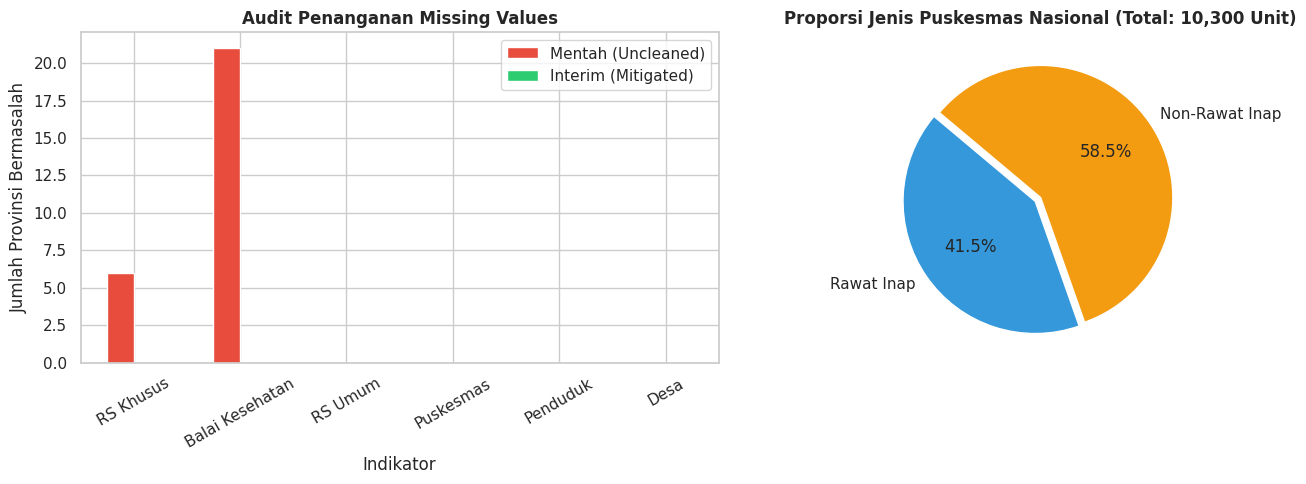

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Missing values audit
missing_audit = pd.DataFrame({
    "Indikator": ["RS Khusus", "Balai Kesehatan", "RS Umum", "Puskesmas", "Penduduk", "Desa"],
    "Mentah (Uncleaned)": [6, 21, 0, 0, 0, 0],
    "Interim (Mitigated)": [
        interim_merged["jumlah_rs_khusus_imputed"].isna().sum(),
        interim_merged["desa_memiliki_balai_kesehatan"].isna().sum(),
        interim_merged["jumlah_rs_umum"].isna().sum(),
        interim_merged["total_puskesmas"].isna().sum(),
        interim_merged["total_penduduk_jiwa"].isna().sum(),
        interim_merged["jumlah_desa"].isna().sum()
    ]
})

missing_audit.plot(
    x="Indikator",
    y=["Mentah (Uncleaned)", "Interim (Mitigated)"],
    kind="bar",
    color=["#e74c3c", "#2ecc71"],
    ax=axes[0],
    rot=30
)
axes[0].set_title("Audit Penanganan Missing Values", weight="bold")
axes[0].set_ylabel("Jumlah Provinsi Bermasalah")

# Plot 2: Distribusi Puskesmas Rawat Inap vs Non-Rawat Inap
pkm_dist = interim_merged[["jumlah_puskesmas_rawat_inap", "jumlah_puskesmas_non_rawat_inap"]].sum()
axes[1].pie(
    pkm_dist,
    labels=["Rawat Inap", "Non-Rawat Inap"],
    autopct="%1.1f%%",
    colors=["#3498db", "#f39c12"],
    startangle=140,
    explode=(0.05, 0)
)
axes[1].set_title(f"Proporsi Jenis Puskesmas Nasional (Total: {pkm_dist.sum():,} Unit)", weight="bold")

plt.tight_layout()
plt.show()


## 6. Ekspor Data ke Folder `data/interim/`


In [11]:
from src.cleaning import save_interim_datasets

paths = save_interim_datasets(clean_pend, clean_desa, clean_sarana, clean_rs, interim_merged)

print("Berkas interim berhasil disimpan:")
for key, path in paths.items():
    size_kb = path.stat().st_size / 1024
    print(f" - {path.name:30s} : {size_kb:6.2f} KB | Path: {path}")


Berkas interim berhasil disimpan:
 - penduduk_clean.csv             :   1.97 KB | Path: C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\interim\penduduk_clean.csv
 - desa_clean.csv                 :   0.73 KB | Path: C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\interim\desa_clean.csv
 - sarana_desa_clean.csv          :   1.81 KB | Path: C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\interim\sarana_desa_clean.csv
 - rs_puskesmas_clean.csv         :   1.97 KB | Path: C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\interim\rs_puskesmas_clean.csv
 - faskes_interim_clean.csv       :   4.84 KB | Path: C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pem

## 7. Ringkasan & Next Steps

**Keputusan Pembersihan yang Diterapkan**
1. **38 Provinsi Bersih**: Seluruh dataset telah diselaraskan ke 38 entitas provinsi resmi pasca DOB Papua.
2. **Missing Value RS Khusus**: 6 provinsi tanpa data RS Khusus dilengkapi dengan kolom flag `rs_khusus_is_missing` dan versi estimasi `total_rs_est` (dengan asumsi 0) agar perhitungan komposit di langkah selanjutnya tidak menghasilkan baris hilang.
3. **Missing Value Balai Kesehatan**: 21 provinsi dengan simbol `\ufffd` dicatat dengan flag `balai_kesehatan_is_missing` dan diimputasi 0.
4. **Validasi 100% Cocok**: Seluruh total akumulasi 38 provinsi terbukti sesuai dengan angka agregat nasional BPS/Kemenkes.

**Langkah Selanjutnya (`03_feature_engineering.ipynb`)**
- Menghitung rasio faskes per 100.000 penduduk (`pkm_per_100k`, `rs_per_100k`).
- Menghitung rasio faskes per satuan luas wilayah km² (`pkm_per_1000km2`).
- Menghitung rasio keterjangkauan desa (`pct_desa_memiliki_pkm`, `pct_desa_memiliki_rs`).
- Menghitung gap kebutuhan faskes berdasarkan standar Permenkes / WHO.
